# Ir Além — Transfer Learning, Fine Tuning e Segmentação Automática

**FIAP — Fase 6 · Opção 2 do "Ir Além"**

Problema: classificar imagens em **vaca** ou **trator** com um dataset pequeno (80 imagens: 32/4/4 por classe em treino/validação/teste).

Este notebook é autossuficiente, testa **duas hipóteses** (Partes A e B) e as compara numa **terceira parte** (C):

1. **Parte A — Transfer Learning + Fine Tuning (hipótese A):** uma rede grande pré-treinada na ImageNet (MobileNetV2) supera uma CNN treinada do zero com os mesmos dados, sementes e divisão?
2. **Parte B — Segmentação automática (hipótese B):** recortar o objeto principal (fundo preto) antes de classificar melhora a acurácia?
3. **Parte C — Comparação final** das 4 combinações (do zero / transfer × original / segmentada), com tempos de treino e de inferência, variância entre sementes, validação cruzada e limitações.

![Pipeline](https://raw.githubusercontent.com/leticiael/leticiaeltermann-fiap-fase6-visao-computacional/main/ir_alem/figuras/pipeline.png)

## 0. Configuração do ambiente

Detecta se está no Google Colab. No Colab, monta o Google Drive, aponta para `/content/drive/MyDrive/fiap_fase6` e instala o `ultralytics` **na versão testada (8.4.175)**, se a versão instalada for outra. Localmente, usa a pasta do projeto (o pai de `ir_alem/`). Também define as pastas de saída: figuras, dataset segmentado e cache de pesos.

No Colab o dataset segmentado vai para `/content/dataset_segmentado` (disco local da VM), e não para o Drive. São 160 arquivos pequenos (imagens + máscaras): gravar no Drive montado é lento e ele não precisa persistir, porque é regenerado de forma determinística em menos de 1 minuto na GPU. As figuras e CSVs, que são entregáveis, continuam no Drive. Os pesos dos modelos (YOLO-World, SAM 2 e CLIP, ~650 MB) ficam em `~/.cache`, fora do projeto.

In [1]:
import importlib
import importlib.metadata
import importlib.util
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
ULTRALYTICS_VERSION = "8.4.175"


def mount_drive():
    from google.colab import drive
    drive.mount("/content/drive")


def installed_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def ensure_package(name, version):
    if installed_version(name) != version:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"{name}=={version}"], check=True)


def find_project_dir():
    if IN_COLAB:
        return Path("/content/drive/MyDrive/fiap_fase6")
    here = Path.cwd().resolve()
    return here.parent if here.name == "ir_alem" else here


if IN_COLAB:
    mount_drive()
    ensure_package("ultralytics", ULTRALYTICS_VERSION)

PROJECT_DIR = find_project_dir()
DATASET_DIR = PROJECT_DIR / "dataset" / "images"
IR_ALEM_DIR = PROJECT_DIR / "ir_alem"
FIGURES_DIR = IR_ALEM_DIR / "figuras"
SEGMENTED_DIR = Path("/content/dataset_segmentado") if IN_COLAB else IR_ALEM_DIR / "dataset_segmentado"
WEIGHTS_DIR = Path.home() / ".cache" / "fiap_ir_alem_pesos"

for folder in (FIGURES_DIR, SEGMENTED_DIR, WEIGHTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Colab: {IN_COLAB}")
print(f"Dataset: {DATASET_DIR}")
print(f"Saídas: {IR_ALEM_DIR}")
print(f"ultralytics: {installed_version('ultralytics')}")

Colab: False
Dataset: C:\Users\leelt\fiap-fase6\dataset\images
Saídas: C:\Users\leelt\fiap-fase6\ir_alem
ultralytics: 8.4.175


### Bibliotecas, dispositivos e constantes globais

Concentra todas as importações e as constantes do experimento: classes (deduzidas do prefixo do nome do arquivo), resolução 224×224, sementes repetidas, hiperparâmetros de treino, aumento de dados e tamanho das figuras. Todas as combinações usam **exatamente** as mesmas sementes e a mesma divisão treino/validação/teste.

Logo após importar o TensorFlow, ativa o *memory growth* em cada GPU. Sem isso, no Colab o TensorFlow reserva quase toda a VRAM e o PyTorch (YOLO-World, CLIP e SAM 2, na Parte B) falha por falta de memória. A célula imprime o dispositivo usado pelo TensorFlow (`TF_DEVICE`) e pelo PyTorch (`TORCH_DEVICE`); os tempos da Parte C se referem a esses dispositivos. Também define formatadores com vírgula decimal para os textos gerados em português.

In [2]:
import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import time
import warnings

import tensorflow as tf


def enable_gpu_memory_growth():
    for gpu in tf.config.list_physical_devices("GPU"):
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError as error:
            print(f"Memory growth não ativado em {gpu.name} (GPU já inicializada): {error}")


enable_gpu_memory_growth()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from PIL import Image
from sklearn.model_selection import StratifiedKFold
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import mobilenet_v2
from ultralytics import SAM, YOLOWorld

warnings.filterwarnings("ignore", category=FutureWarning, module="torch")
tf.get_logger().setLevel("ERROR")

CLASSES = ("vaca", "trator")
SPLITS = ("train", "val", "test")
IMG_SIZE = 224
BATCH_SIZE = 16
SEEDS = (42, 7, 2024)
DECISION_THRESHOLD = 0.5
LOG_LOSS_EPSILON = 1e-7
INFERENCE_REPEATS = 5

AUGMENT_ROTATION = 0.08
AUGMENT_ZOOM = 0.15
AUGMENT_CONTRAST = 0.15

SCRATCH_EPOCHS = 40
SCRATCH_LR = 1e-3
SCRATCH_BN_MOMENTUM = 0.9
SCRATCH_FILTERS = (32, 64, 128, 256)
SCRATCH_DROPOUT = 0.4
TRANSFER_DROPOUT = 0.3
HEAD_EPOCHS = 15
HEAD_LR = 1e-3
FINE_TUNE_EPOCHS = 10
FINE_TUNE_LR = 1e-5
FINE_TUNE_FROM_LAYER = "block_15_expand"

FIGURE_DPI = 130
PHOTO_GRID_DPI = 90

MODEL_SCRATCH = "CNN do zero"
MODEL_TRANSFER = "MobileNetV2 (transfer + fine tuning)"
VARIANT_ORIGINAL = "Original"
VARIANT_SEGMENTED = "Segmentada"

TF_DEVICE = "GPU" if tf.config.list_physical_devices("GPU") else "CPU"
TORCH_DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"


def decimal(value, digits=1):
    return f"{value:.{digits}f}".replace(".", ",")


def percent(value, digits=1):
    return f"{decimal(100 * value, digits)}%"


def thousands(value):
    return f"{value:,}".replace(",", ".")


print(f"TensorFlow {tf.__version__} · dispositivo de treino (TF_DEVICE): {TF_DEVICE}")
print(f"PyTorch {torch.__version__} · dispositivo da segmentação (TORCH_DEVICE): {TORCH_DEVICE}")

TensorFlow 2.19.0 · dispositivo de treino (TF_DEVICE): CPU
PyTorch 2.14.1+cu126 · dispositivo da segmentação (TORCH_DEVICE): cuda:0


### Figura autoral do pipeline

Desenha com `matplotlib` (caixas e setas) o fluxo completo do experimento, salva em `figuras/pipeline.png` e exibe a figura.

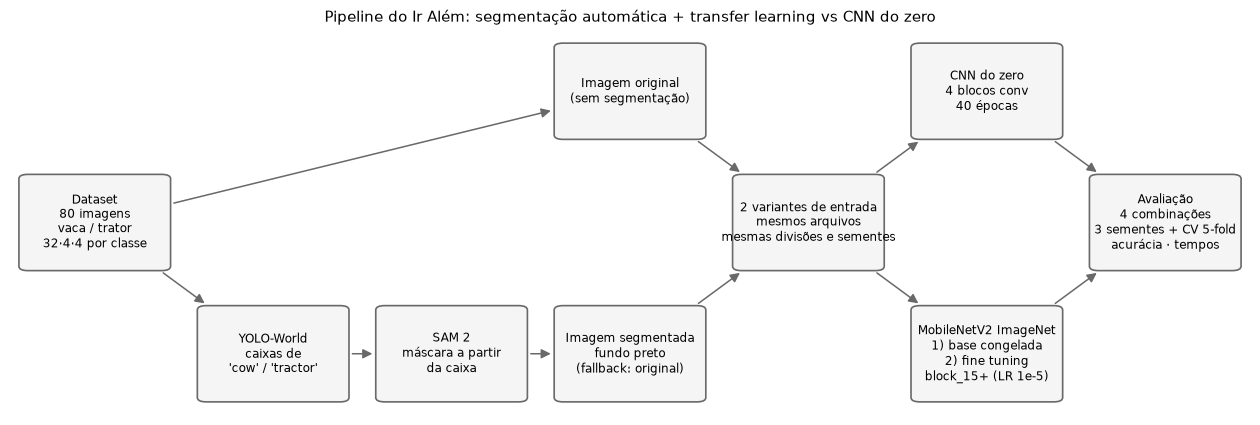

In [3]:
PIPELINE_BOXES = {
    "dados": (0.00, 0.42, "Dataset\n80 imagens\nvaca / trator\n32·4·4 por classe"),
    "detector": (0.20, 0.12, "YOLO-World\ncaixas de\n'cow' / 'tractor'"),
    "sam": (0.40, 0.12, "SAM 2\nmáscara a partir\nda caixa"),
    "segmentada": (0.60, 0.12, "Imagem segmentada\nfundo preto\n(fallback: original)"),
    "original": (0.60, 0.72, "Imagem original\n(sem segmentação)"),
    "variantes": (0.80, 0.42, "2 variantes de entrada\nmesmos arquivos\nmesmas divisões e sementes"),
    "zero": (1.00, 0.72, "CNN do zero\n4 blocos conv\n40 épocas"),
    "transfer": (1.00, 0.12, "MobileNetV2 ImageNet\n1) base congelada\n2) fine tuning\nblock_15+ (LR 1e-5)"),
    "avaliacao": (1.20, 0.42, "Avaliação\n4 combinações\n3 sementes + CV 5-fold\nacurácia · tempos"),
}
PIPELINE_ARROWS = (
    ("dados", "original"), ("dados", "detector"), ("detector", "sam"), ("sam", "segmentada"),
    ("original", "variantes"), ("segmentada", "variantes"),
    ("variantes", "zero"), ("variantes", "transfer"), ("zero", "avaliacao"), ("transfer", "avaliacao"),
)
BOX_WIDTH, BOX_HEIGHT = 0.15, 0.2


def box_center(key):
    x, y, _ = PIPELINE_BOXES[key]
    return x + BOX_WIDTH / 2, y + BOX_HEIGHT / 2


def draw_box(ax, key):
    x, y, text = PIPELINE_BOXES[key]
    patch = FancyBboxPatch((x, y), BOX_WIDTH, BOX_HEIGHT, boxstyle="round,pad=0.01",
                           facecolor="whitesmoke", edgecolor="dimgray", linewidth=1.2)
    ax.add_patch(patch)
    ax.text(x + BOX_WIDTH / 2, y + BOX_HEIGHT / 2, text, ha="center", va="center", fontsize=8.5)
    return patch


def draw_arrow(ax, patches, start, end):
    ax.add_patch(FancyArrowPatch(box_center(start), box_center(end), patchA=patches[start], patchB=patches[end],
                                 arrowstyle="-|>", mutation_scale=14, color="dimgray", shrinkA=2, shrinkB=2,
                                 linewidth=1.1))


def draw_pipeline(path):
    fig, ax = plt.subplots(figsize=(16, 5))
    patches = {key: draw_box(ax, key) for key in PIPELINE_BOXES}
    for start, end in PIPELINE_ARROWS:
        draw_arrow(ax, patches, start, end)
    ax.set_xlim(-0.02, 1.37)
    ax.set_ylim(0.08, 0.96)
    ax.axis("off")
    ax.set_title("Pipeline do Ir Além: segmentação automática + transfer learning vs CNN do zero", fontsize=11)
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()


draw_pipeline(FIGURES_DIR / "pipeline.png")

### Carregamento dos dados

Lê as imagens de cada split, redimensiona para 224×224 (tamanho nativo da MobileNetV2 na ImageNet) e extrai o rótulo do prefixo do nome (`vaca_NNN.jpg` → 0, `trator_NNN.jpg` → 1). O redimensionamento é direto (sem recorte central) para não cortar o objeto, que costuma ocupar boa parte do quadro. Os pixels ficam em `[0, 255]`; cada modelo aplica o próprio pré-processamento dentro do grafo.

In [4]:
def label_from_path(path):
    return CLASSES.index(path.stem.split("_")[0])


def load_image(path):
    image = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.asarray(image, dtype=np.float32)


def list_images(root, split):
    return sorted(path for path in (root / split).iterdir() if path.suffix.lower() in {".jpg", ".jpeg", ".png"})


def load_split(root, split):
    paths = list_images(root, split)
    images = np.stack([load_image(path) for path in paths])
    labels = np.array([label_from_path(path) for path in paths], dtype=np.float32)
    return {"paths": paths, "x": images, "y": labels}


def load_dataset(root):
    return {split: load_split(root, split) for split in SPLITS}


original_data = load_dataset(DATASET_DIR)
for split, part in original_data.items():
    counts = {name: int((part["y"] == index).sum()) for index, name in enumerate(CLASSES)}
    print(f"{split:5s}: {len(part['y'])} imagens {counts}")

train: 64 imagens {'vaca': 32, 'trator': 32}
val  : 8 imagens {'vaca': 4, 'trator': 4}
test : 8 imagens {'vaca': 4, 'trator': 4}


---
## Parte A — Transfer Learning + Fine Tuning (TensorFlow/Keras)

### Por que MobileNetV2?

* **Dataset minúsculo (64 imagens de treino):** treinar milhões de pesos do zero leva a overfitting; reaproveitar filtros aprendidos em 1,28 milhão de imagens da ImageNet (que **contém** classes de bovinos e de veículos agrícolas/tratores) dá representações prontas.
* **Leve e rápida:** ~2,3 M parâmetros na base convolucional (~14 MB). Treina em poucos minutos mesmo sem GPU, então o notebook roda em qualquer máquina; o dispositivo efetivamente usado é o `TF_DEVICE` impresso na célula de bibliotecas.
* **Boa acurácia na ImageNet** (~71,3% top-1) para o custo, com convoluções separáveis em profundidade e blocos *inverted residual*.
* Alternativas maiores (ResNet50, EfficientNetB3) teriam mais capacidade do que 64 imagens conseguem ajustar e custariam muito mais tempo.

### Pré-processamento

* **224×224:** resolução em que os pesos ImageNet foram treinados; mantém a escala dos filtros.
* **`mobilenet_v2.preprocess_input`:** a MobileNetV2 foi treinada com pixels em `[-1, 1]` (`x/127.5 − 1`). Usar outra escala deslocaria as ativações dos BatchNorms congelados. O passo está **dentro** do modelo (após o aumento), então o modelo recebe pixels crus.
* **Aumento de dados** (só no treino): flip horizontal, rotação de ±8% de volta (≈ ±29°), zoom ±15% e contraste ±15%. São transformações plausíveis para fotos de campo (uma vaca espelhada continua sendo vaca) e combatem a memorização das 64 imagens. Sem flip vertical: vacas e tratores de cabeça para baixo não existem no problema.

### Blocos de construção dos modelos

Define o aumento de dados compartilhado, a **CNN do zero** (baseline compacto: 4 blocos Conv-BN-ReLU-MaxPool com 32→256 filtros, *global average pooling*, dropout 0,4 e saída sigmoide; pixels escalados para `[0, 1]`; BatchNorm com `momentum=0.9`) e a **MobileNetV2** com cabeça nova (GAP → Dropout 0,3 → Dense sigmoide). A base é chamada com `training=False` e, no fine tuning, as camadas BatchNorm continuam **congeladas** (ver abaixo) — com lotes de 16 imagens, atualizar suas médias destruiria as estatísticas da ImageNet.

In [5]:
def build_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(AUGMENT_ROTATION),
        layers.RandomZoom(AUGMENT_ZOOM),
        layers.RandomContrast(AUGMENT_CONTRAST),
    ], name="aumento_de_dados")


def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization(momentum=SCRATCH_BN_MOMENTUM)(x)
    x = layers.Activation("relu")(x)
    return layers.MaxPooling2D()(x)


def classification_head(x, dropout):
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return layers.Dense(1, activation="sigmoid")(x)


def build_scratch_model():
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = build_augmentation()(inputs)
    x = layers.Rescaling(1 / 255)(x)
    for filters in SCRATCH_FILTERS:
        x = conv_block(x, filters)
    return keras.Model(inputs, classification_head(x, SCRATCH_DROPOUT), name="cnn_do_zero")


def build_mobilenet_base():
    return keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")


def build_transfer_model():
    base = build_mobilenet_base()
    base.trainable = False
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = build_augmentation()(inputs)
    x = layers.Lambda(mobilenet_v2.preprocess_input, name="preprocess_mobilenet_v2")(x)
    x = base(x, training=False)
    return keras.Model(inputs, classification_head(x, TRANSFER_DROPOUT), name="mobilenetv2_transfer"), base


def compile_model(model, learning_rate):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss="binary_crossentropy", metrics=["accuracy"])

> **Armadilha encontrada durante o desenvolvimento:** com o `momentum=0.99` padrão do Keras, as médias móveis do BatchNorm da CNN do zero recebem só 4 lotes por época (160 atualizações em 40 épocas, `0,99^160 ≈ 20%` ainda do valor inicial). No modo de inferência o modelo usava estatísticas erradas e previa uma única classe para tudo (acurácia de 50%, o acaso, até nas próprias imagens de **treino**, embora a acurácia exibida durante o `fit` fosse alta). Com `momentum=0.9` as médias convergem e o baseline fica justo.

### Qual camada descongelar no fine tuning?

Lista o fim da MobileNetV2 para localizar o ponto de corte. A base tem 154 camadas organizadas em 17 blocos *inverted residual*. Descongelamos a partir de **`block_15_expand`**, ou seja, os **dois últimos blocos (15 e 16) + `Conv_1`**:

* As camadas iniciais aprendem bordas, cores e texturas genéricas — úteis para qualquer foto e caras de reajustar com 64 imagens.
* Os blocos 15–16 (7×7, 160→320 canais) e a `Conv_1` (1280 canais) codificam partes de objetos específicas das classes ImageNet; são eles que precisam ser adaptados para "vaca vs trator".
* Descongelar mais (ex.: a partir do bloco 13) multiplicaria os pesos treináveis com o mesmo punhado de exemplos → overfitting e esquecimento catastrófico. Com LR baixo (1e-5, 100× menor que o da cabeça) os pesos pré-treinados só são ajustados finamente.
* **BatchNorm fica congelado mesmo dentro dos blocos descongelados.** Testamos: no Keras 3, um BN com `trainable=True` volta a usar as estatísticas do lote mesmo com `training=False` na chamada da base. Num teste preliminar com lotes de 16 imagens, isso derrubou a acurácia de treino logo na primeira época de fine tuning e multiplicou a perda. Com os BNs congelados, o fine tuning continua de onde o estágio 1 parou e a perda segue caindo (ver as curvas abaixo).

In [6]:
def layer_index(model, name):
    return next(index for index, layer in enumerate(model.layers) if layer.name == name)


def count_parameters(weights):
    return int(sum(np.prod(weight.shape) for weight in weights))


def is_fine_tunable(index, layer):
    return index >= FINE_TUNE_FROM_INDEX and not isinstance(layer, layers.BatchNormalization)


inspection_base = build_mobilenet_base()
FINE_TUNE_FROM_INDEX = layer_index(inspection_base, FINE_TUNE_FROM_LAYER)
unfrozen_layers = [layer for index, layer in enumerate(inspection_base.layers)
                   if is_fine_tunable(index, layer) and layer.weights]
unfrozen_parameters = count_parameters([w for layer in unfrozen_layers for w in layer.trainable_weights])

print(f"Camadas na base: {len(inspection_base.layers)}")
print(f"Descongelar a partir do índice {FINE_TUNE_FROM_INDEX} ({FINE_TUNE_FROM_LAYER}): "
      f"{len(unfrozen_layers)} camadas com pesos treináveis (BatchNorm excluído)")
print(f"Parâmetros treináveis no fine tuning: {thousands(unfrozen_parameters)} de {thousands(inspection_base.count_params())}")
print([layer.name for layer in unfrozen_layers])

Camadas na base: 154
Descongelar a partir do índice 134 (block_15_expand): 7 camadas com pesos treináveis (BatchNorm excluído)
Parâmetros treináveis no fine tuning: 1.194.880 de 2.257.984
['block_15_expand', 'block_15_depthwise', 'block_15_project', 'block_16_expand', 'block_16_depthwise', 'block_16_project', 'Conv_1']


### Treino e avaliação

Funções de treino:

* **CNN do zero:** 40 épocas, Adam 1e-3.
* **Transfer:** estágio 1 = 15 épocas com a base congelada (Adam 1e-3, só a cabeça aprende); estágio 2 = 10 épocas com `block_15_expand` em diante descongelado (Adam 1e-5). A cabeça é treinada primeiro para que gradientes grandes de uma camada aleatória não estraguem os pesos pré-treinados.

Não há *early stopping*: a validação tem só 8 imagens, então parar "no melhor val" seria escolher ruído. A avaliação mede acurácia em validação, teste e **validação+teste (16 imagens)** com limiar de decisão 0,5, o tempo de treino e o tempo de inferência por imagem (média de 5 passadas pelo teste, após aquecimento). As predições usam a chamada direta `model(x, training=False)` em lotes de 16, em vez de `model.predict`, que recompila (*retracing*) a função a cada novo modelo e polui a saída com avisos.

In [7]:
def fit(model, data, epochs):
    history = model.fit(data["train"]["x"], data["train"]["y"], batch_size=BATCH_SIZE, epochs=epochs,
                        validation_data=(data["val"]["x"], data["val"]["y"]), shuffle=True, verbose=0)
    return history.history


def merge_histories(*histories):
    return {key: sum((history[key] for history in histories), []) for key in histories[0]}


def unfreeze_top(base):
    base.trainable = True
    for index, layer in enumerate(base.layers):
        layer.trainable = is_fine_tunable(index, layer)


def train_scratch(data):
    model = build_scratch_model()
    compile_model(model, SCRATCH_LR)
    return model, fit(model, data, SCRATCH_EPOCHS)


def train_transfer(data):
    model, base = build_transfer_model()
    compile_model(model, HEAD_LR)
    head_history = fit(model, data, HEAD_EPOCHS)
    unfreeze_top(base)
    compile_model(model, FINE_TUNE_LR)
    return model, merge_histories(head_history, fit(model, data, FINE_TUNE_EPOCHS))


TRAINERS = {MODEL_SCRATCH: train_scratch, MODEL_TRANSFER: train_transfer}


def predict(model, x):
    batches = [model(tf.constant(x[start:start + BATCH_SIZE]), training=False) for start in range(0, len(x), BATCH_SIZE)]
    return np.concatenate([batch.numpy() for batch in batches]).ravel()


def accuracy(model, x, y):
    return float(((predict(model, x) > DECISION_THRESHOLD) == y.astype(bool)).mean())


def log_loss(model, x, y):
    probabilities = np.clip(predict(model, x), LOG_LOSS_EPSILON, 1 - LOG_LOSS_EPSILON)
    return float(-np.mean(y * np.log(probabilities) + (1 - y) * np.log(1 - probabilities)))


def inference_ms_per_image(model, x):
    predict(model, x)
    start = time.perf_counter()
    for _ in range(INFERENCE_REPEATS):
        predict(model, x)
    return 1000 * (time.perf_counter() - start) / (INFERENCE_REPEATS * len(x))


def evaluate(model, data):
    val_test_x = np.concatenate([data["val"]["x"], data["test"]["x"]])
    val_test_y = np.concatenate([data["val"]["y"], data["test"]["y"]])
    return {
        "acc_treino": accuracy(model, data["train"]["x"], data["train"]["y"]),
        "acc_val": accuracy(model, data["val"]["x"], data["val"]["y"]),
        "acc_teste": accuracy(model, data["test"]["x"], data["test"]["y"]),
        "acc_val_teste": accuracy(model, val_test_x, val_test_y),
        "logloss_val_teste": log_loss(model, val_test_x, val_test_y),
        "inferencia_ms": inference_ms_per_image(model, data["test"]["x"]),
    }


def run_experiment(model_name, variant, data, seed):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    start = time.perf_counter()
    model, history = TRAINERS[model_name](data)
    train_seconds = time.perf_counter() - start
    row = {"modelo": model_name, "imagens": variant, "semente": seed, "tempo_treino_s": train_seconds}
    return {**row, **evaluate(model, data)}, history


def run_all_seeds(model_name, variant, data):
    rows, histories = [], {}
    for seed in SEEDS:
        row, histories[seed] = run_experiment(model_name, variant, data, seed)
        rows.append(row)
        print(f"{model_name} | {variant} | semente {seed}: val {percent(row['acc_val'])} · teste {percent(row['acc_teste'])} "
              f"· val+teste {percent(row['acc_val_teste'])} · treino {decimal(row['tempo_treino_s'], 0)} s")
    return rows, histories

### Execução — imagens originais

Treina os dois modelos nas imagens originais com as 3 sementes.

In [8]:
all_rows, all_histories = [], {}
for model_name in TRAINERS:
    rows, histories = run_all_seeds(model_name, VARIANT_ORIGINAL, original_data)
    all_rows += rows
    all_histories[(model_name, VARIANT_ORIGINAL)] = histories

CNN do zero | Original | semente 42: val 75,0% · teste 100,0% · val+teste 87,5% · treino 52 s


CNN do zero | Original | semente 7: val 87,5% · teste 100,0% · val+teste 93,8% · treino 51 s


CNN do zero | Original | semente 2024: val 50,0% · teste 75,0% · val+teste 62,5% · treino 51 s


MobileNetV2 (transfer + fine tuning) | Original | semente 42: val 100,0% · teste 100,0% · val+teste 100,0% · treino 24 s


MobileNetV2 (transfer + fine tuning) | Original | semente 7: val 100,0% · teste 100,0% · val+teste 100,0% · treino 25 s


MobileNetV2 (transfer + fine tuning) | Original | semente 2024: val 100,0% · teste 100,0% · val+teste 100,0% · treino 25 s


### Curvas de aprendizado (semente 42)

Plota acurácia de treino e validação por época. Na MobileNetV2 a linha tracejada marca o início do fine tuning.

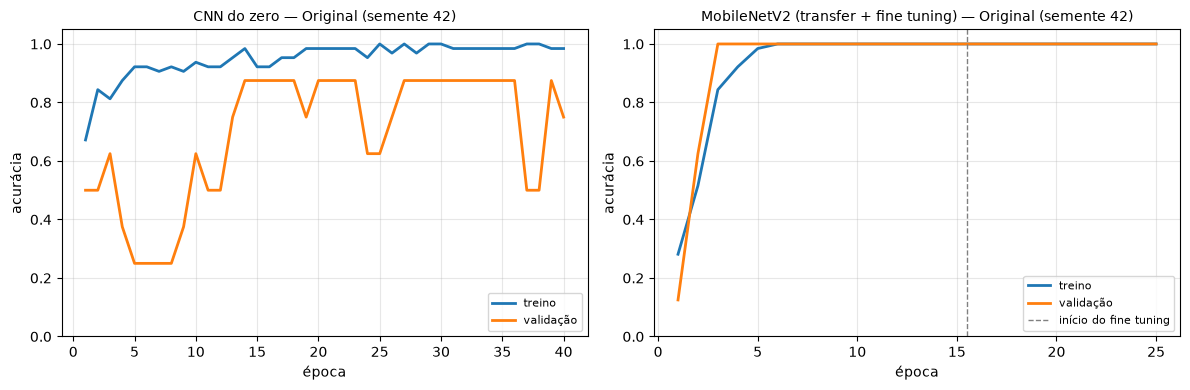

In [9]:
def plot_curves(ax, history, title, boundary=None):
    epochs = np.arange(1, len(history["accuracy"]) + 1)
    ax.plot(epochs, history["accuracy"], label="treino", linewidth=2)
    ax.plot(epochs, history["val_accuracy"], label="validação", linewidth=2)
    if boundary:
        ax.axvline(boundary + 0.5, color="gray", linestyle="--", linewidth=1, label="início do fine tuning")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("época")
    ax.set_ylabel("acurácia")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="lower right")


def plot_learning_curves(variant, path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, model_name in zip(axes, TRAINERS):
        boundary = HEAD_EPOCHS if model_name == MODEL_TRANSFER else None
        title = f"{model_name} — {variant} (semente {SEEDS[0]})"
        plot_curves(ax, all_histories[(model_name, variant)][SEEDS[0]], title, boundary)
    fig.tight_layout()
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()


plot_learning_curves(VARIANT_ORIGINAL, FIGURES_DIR / "curvas_original.png")

### Resultado da Parte A

Resume média ± desvio-padrão sobre as 3 sementes para as imagens originais (vírgula decimal).

In [10]:
METRICS = ["acc_treino", "acc_val", "acc_teste", "acc_val_teste", "logloss_val_teste", "tempo_treino_s", "inferencia_ms"]


def format_column(column):
    return column.map(lambda value: decimal(value, 3))


def summarize(rows):
    grouped = pd.DataFrame(rows).groupby(["modelo", "imagens"], sort=False)[METRICS]
    mean, std = grouped.mean(), grouped.std()
    return mean.combine(std, lambda means, stds: format_column(means) + " ± " + format_column(stds))


summarize(all_rows)

,,acc_treino,acc_val,acc_teste,acc_val_teste,logloss_val_teste,tempo_treino_s,inferencia_ms
modelo,imagens,,,,,,,
CNN do zero,Original,"0,922 ± 0,095","0,708 ± 0,191","0,917 ± 0,144","0,812 ± 0,165","0,846 ± 0,503","51,289 ± 0,322","7,090 ± 0,194"
MobileNetV2 (transfer + fine tuning),Original,"1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","0,002 ± 0,001","24,318 ± 0,566","28,030 ± 0,236"


**Hipótese A — a rede pré-treinada supera a treinada do zero?** A conclusão com os números finais está na Parte C. A expectativa teórica é que sim: com 64 imagens a CNN do zero precisa aprender filtros de borda, textura e forma sem dados suficientes, enquanto a MobileNetV2 já chega com esses filtros prontos.

---
## Parte B — Segmentação automática do objeto principal

### Estratégia (100% automática, igual para as duas classes)

1. **Detector de vocabulário aberto — YOLO-World (`yolov8x-worldv2`)** com os prompts de texto `"cow"` e `"tractor"`. O COCO não tem a classe *trator*, então um YOLO-seg comum só serviria para as vacas; o YOLO-World resolve as duas classes com o **mesmo** procedimento.
2. **SAM 2 (`sam2_b`)** recebe as caixas detectadas como *prompt* e devolve uma máscara precisa do contorno. A união das máscaras cobre rebanhos (várias vacas) e trator + implemento.
3. **A classe prevista pelo detector é descartada** — só a geometria (caixa) é usada, e as duas palavras são sempre enviadas juntas. Assim o rótulo não "vaza" diretamente para o classificador (ver limitações na Parte C).
4. **Fallback:** se não houver detecção com confiança ≥ 0,15 ou se a máscara cobrir menos de 2% da imagem, usa-se a imagem inteira. A contagem de fallbacks é reportada.

### Por que fundo preto?

* No pré-processamento da MobileNetV2 o preto vira `−1` e na CNN do zero vira `0`: um valor constante, sem textura, que gera pouca ativação nas convoluções — o modelo "vê" só o objeto.
* Fundo branco (`+1`) seria facilmente confundido com céu claro, neve ou partes brancas de vacas holandesas, criando bordas artificiais fortes no contorno.

### Carregamento do detector e do segmentador

Carrega o YOLO-World com o vocabulário fixo `cow`/`tractor` e o SAM 2, no dispositivo `TORCH_DEVICE`. Os pesos são baixados uma única vez para uma pasta de cache fora do projeto. O codificador de texto CLIP do YOLO-World normalmente seria baixado em `./weights/clip` (relativo à pasta atual, ou seja, dentro do repositório). Por isso a pasta de pesos do módulo `ultralytics.nn.text_model` é redirecionada para o mesmo cache, só nesta sessão e sem alterar as configurações globais do ultralytics. O redirecionamento só é aplicado se o módulo tiver esse atributo (testado na versão 8.4.175); em outra versão o notebook avisa e segue.

In [11]:
TEXT_MODEL_MODULE = "ultralytics.nn.text_model"
DETECTOR_WEIGHTS = "yolov8x-worldv2.pt"
SEGMENTER_WEIGHTS = "sam2_b.pt"
DETECTION_PROMPTS = ["cow", "tractor"]
MIN_CONFIDENCE = 0.15
MIN_MASK_FRACTION = 0.02
MAX_BOXES = 6


def redirect_clip_weights(folder):
    module = importlib.import_module(TEXT_MODEL_MODULE) if importlib.util.find_spec(TEXT_MODEL_MODULE) else None
    if hasattr(module, "WEIGHTS_DIR"):
        module.WEIGHTS_DIR = folder
    else:
        print(f"Aviso: {TEXT_MODEL_MODULE}.WEIGHTS_DIR não existe nesta versão; o CLIP usará a pasta padrão do ultralytics.")


def load_segmenters():
    redirect_clip_weights(WEIGHTS_DIR)
    detector = YOLOWorld(str(WEIGHTS_DIR / DETECTOR_WEIGHTS))
    detector.set_classes(DETECTION_PROMPTS)
    return detector, SAM(str(WEIGHTS_DIR / SEGMENTER_WEIGHTS))


detector, segmenter = load_segmenters()
print(f"Detector e segmentador carregados em {TORCH_DEVICE}")

Detector e segmentador carregados em cuda:0


### Funções de segmentação

`detect_boxes` devolve as caixas mais confiáveis (até 6); `segment_object` pede ao SAM 2 uma máscara por caixa e faz a união; `apply_mask` zera o fundo na imagem **original em resolução cheia**; `segment_image` aplica o fallback e devolve também os metadados (nº de caixas, confiança, área da máscara).

In [12]:
def detect_boxes(image_path):
    boxes = detector.predict(str(image_path), conf=MIN_CONFIDENCE, device=TORCH_DEVICE, verbose=False)[0].boxes
    order = boxes.conf.argsort(descending=True)[:MAX_BOXES]
    return boxes.xyxy[order].cpu().numpy(), boxes.conf[order].cpu().numpy()


def resize_mask(mask, shape):
    if mask.shape == shape:
        return mask
    return np.asarray(Image.fromarray(mask).resize((shape[1], shape[0]), Image.NEAREST))


def segment_object(image_path, boxes, shape):
    masks = segmenter.predict(str(image_path), bboxes=boxes.tolist(), device=TORCH_DEVICE, verbose=False)[0].masks
    union = masks.data.any(dim=0).cpu().numpy().astype(np.uint8) * 255
    return resize_mask(union, shape) > 0


def apply_mask(image, mask):
    return image * mask[..., None].astype(image.dtype)


def segment_image(image_path):
    image = np.asarray(Image.open(image_path).convert("RGB"))
    boxes, confidences = detect_boxes(image_path)
    mask = segment_object(image_path, boxes, image.shape[:2]) if len(boxes) else np.zeros(image.shape[:2], bool)
    fallback = mask.mean() < MIN_MASK_FRACTION
    final_mask = np.ones_like(mask) if fallback else mask
    info = {"caixas": len(boxes), "confianca_max": float(confidences.max()) if len(boxes) else 0.0,
            "area_mascara": float(mask.mean()), "fallback": bool(fallback)}
    return image, final_mask, apply_mask(image, final_mask), info

### Segmentação do dataset inteiro

Percorre os 3 splits, salva a imagem segmentada (mesmo nome, em `SEGMENTED_DIR/<split>/`) e a máscara (`.png`, em `SEGMENTED_DIR/mascaras/<split>/`), e monta uma tabela com os metadados de cada imagem.

In [13]:
MASKS_DIR = SEGMENTED_DIR / "mascaras"


def save_outputs(path, split, mask, masked):
    for folder in (SEGMENTED_DIR / split, MASKS_DIR / split):
        folder.mkdir(parents=True, exist_ok=True)
    Image.fromarray(masked).save(SEGMENTED_DIR / split / path.name, quality=95)
    Image.fromarray(mask.astype(np.uint8) * 255).save(MASKS_DIR / split / f"{path.stem}.png")


def segment_dataset():
    records = []
    for split in SPLITS:
        for path in list_images(DATASET_DIR, split):
            _, mask, masked, info = segment_image(path)
            save_outputs(path, split, mask, masked)
            records.append({"split": split, "arquivo": path.name, "classe": CLASSES[label_from_path(path)], **info})
    return pd.DataFrame(records)


start = time.perf_counter()
segmentation_report = segment_dataset()
segmentation_seconds = time.perf_counter() - start
fallbacks = segmentation_report[segmentation_report["fallback"]]
print(f"Segmentadas {len(segmentation_report)} imagens em {decimal(segmentation_seconds)} s "
      f"({decimal(1000 * segmentation_seconds / len(segmentation_report), 0)} ms/imagem)")
print(f"Fallbacks (imagem inteira): {len(fallbacks)} de {len(segmentation_report)}")
segmentation_report.groupby("classe")[["caixas", "confianca_max", "area_mascara", "fallback"]].mean().style.format(
    precision=3, decimal=",")

Segmentadas 80 imagens em 14,7 s (184 ms/imagem)
Fallbacks (imagem inteira): 0 de 80


,caixas,confianca_max,area_mascara,fallback
classe,,,,
trator,"1,150","0,902","0,373","0,000"
vaca,"2,675","0,956","0,290","0,000"


### Imagens em que a segmentação falhou

Lista as imagens que caíram no fallback (nenhuma detecção confiável ou máscara minúscula) e as de menor confiança de detecção, que merecem inspeção visual.

In [14]:
REPORT_COLUMNS = ["split", "arquivo", "caixas", "confianca_max", "area_mascara"]


def report_table(frame):
    return frame[REPORT_COLUMNS].to_string(index=False, float_format=lambda value: decimal(value, 3))


print("Fallbacks:")
print(report_table(fallbacks) if len(fallbacks) else "nenhum")
print("\nMenor confiança de detecção:")
print(report_table(segmentation_report.nsmallest(5, "confianca_max")))

Fallbacks:
nenhum

Menor confiança de detecção:
split        arquivo  caixas  confianca_max  area_mascara
train trator_025.jpg       2          0,425         0,125
train trator_022.jpg       1          0,530         0,281
train trator_014.jpg       1          0,537         0,215
train trator_012.jpg       2          0,604         0,496
train trator_031.jpg       2          0,611         0,275


### Original | máscara | imagem segmentada

Mostra exemplos das duas classes, espalhados pelos splits, lendo os arquivos já salvos: a imagem original, a máscara binária gerada automaticamente e o resultado com fundo preto.

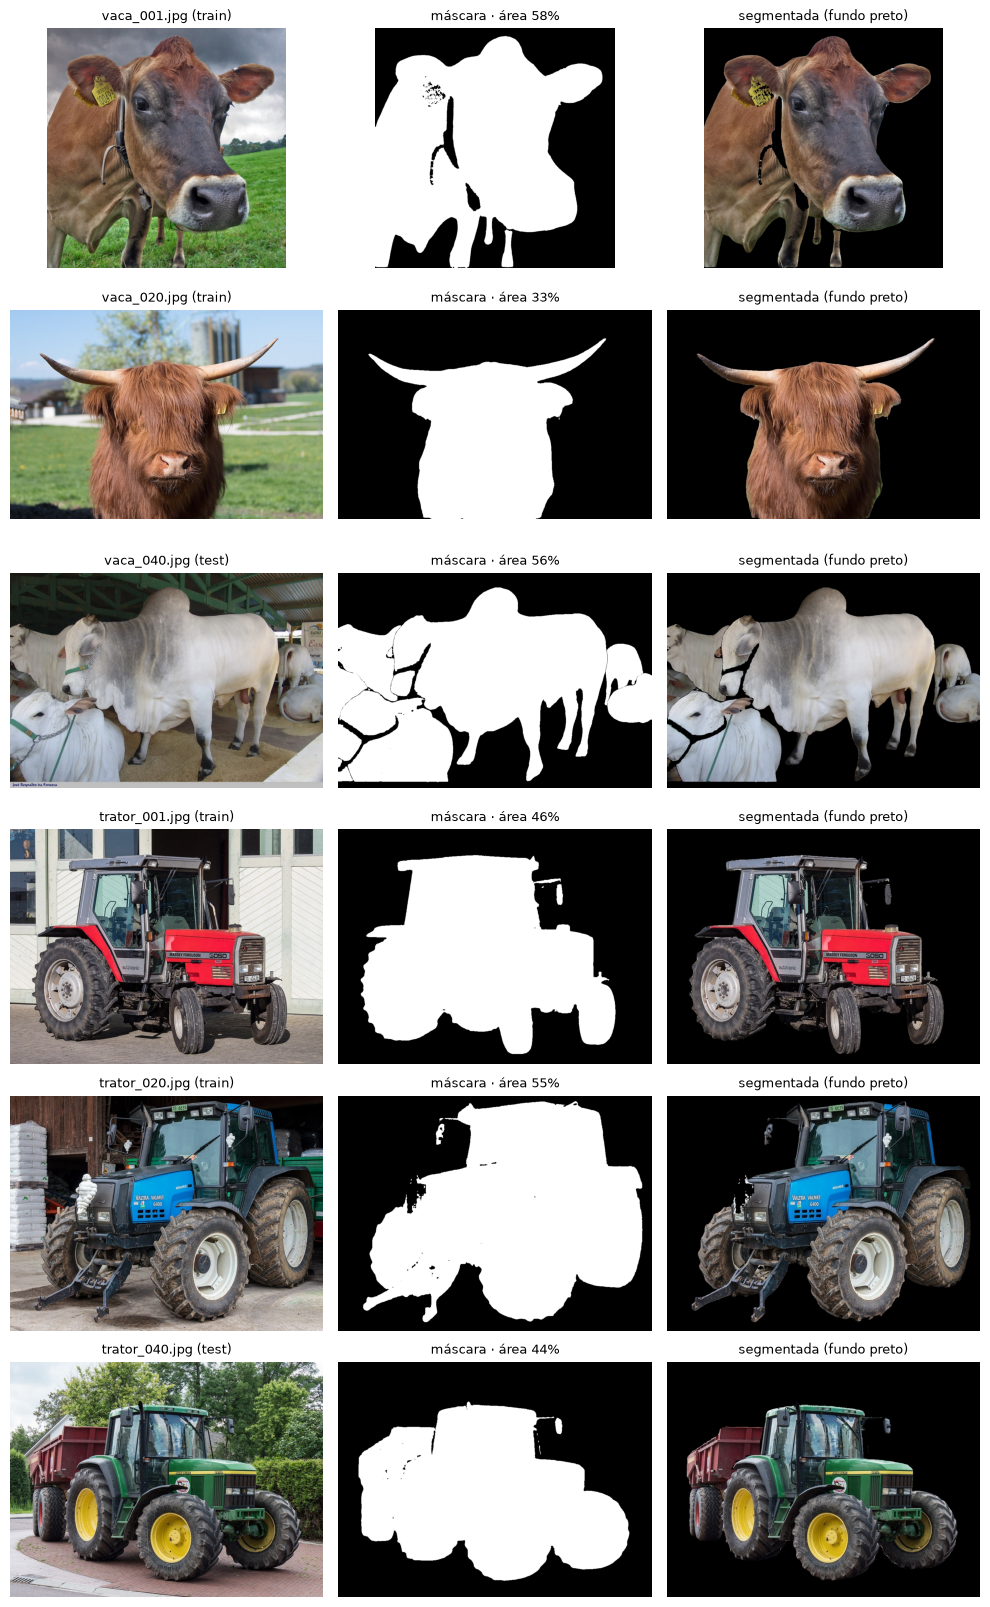

In [15]:
EXAMPLES_PER_CLASS = 3


def pick_examples():
    picks = []
    for name in CLASSES:
        subset = segmentation_report[segmentation_report["classe"] == name]
        picks += subset.iloc[np.linspace(0, len(subset) - 1, EXAMPLES_PER_CLASS).astype(int)].to_dict("records")
    return picks


def load_triplet(record):
    split, name = record["split"], record["arquivo"]
    mask_path = MASKS_DIR / split / f"{Path(name).stem}.png"
    return [Image.open(path) for path in (DATASET_DIR / split / name, mask_path, SEGMENTED_DIR / split / name)]


def plot_triplets(records, path):
    fig, axes = plt.subplots(len(records), 3, figsize=(10, 2.7 * len(records)))
    for row, record in zip(axes, records):
        panels = load_triplet(record)
        titles = (f"{record['arquivo']} ({record['split']})", f"máscara · área {percent(record['area_mascara'], 0)}",
                  "fallback: imagem inteira" if record["fallback"] else "segmentada (fundo preto)")
        for ax, panel, title in zip(row, panels, titles):
            ax.imshow(panel, cmap="gray")
            ax.set_title(title, fontsize=9)
            ax.axis("off")
    fig.tight_layout()
    fig.savefig(path, dpi=PHOTO_GRID_DPI, bbox_inches="tight")
    plt.show()


plot_triplets(pick_examples(), FIGURES_DIR / "segmentacao_exemplos.png")

### Galeria completa das 80 imagens segmentadas

Para não esconder falhas, exibe todas as imagens segmentadas (título em vermelho = fallback).

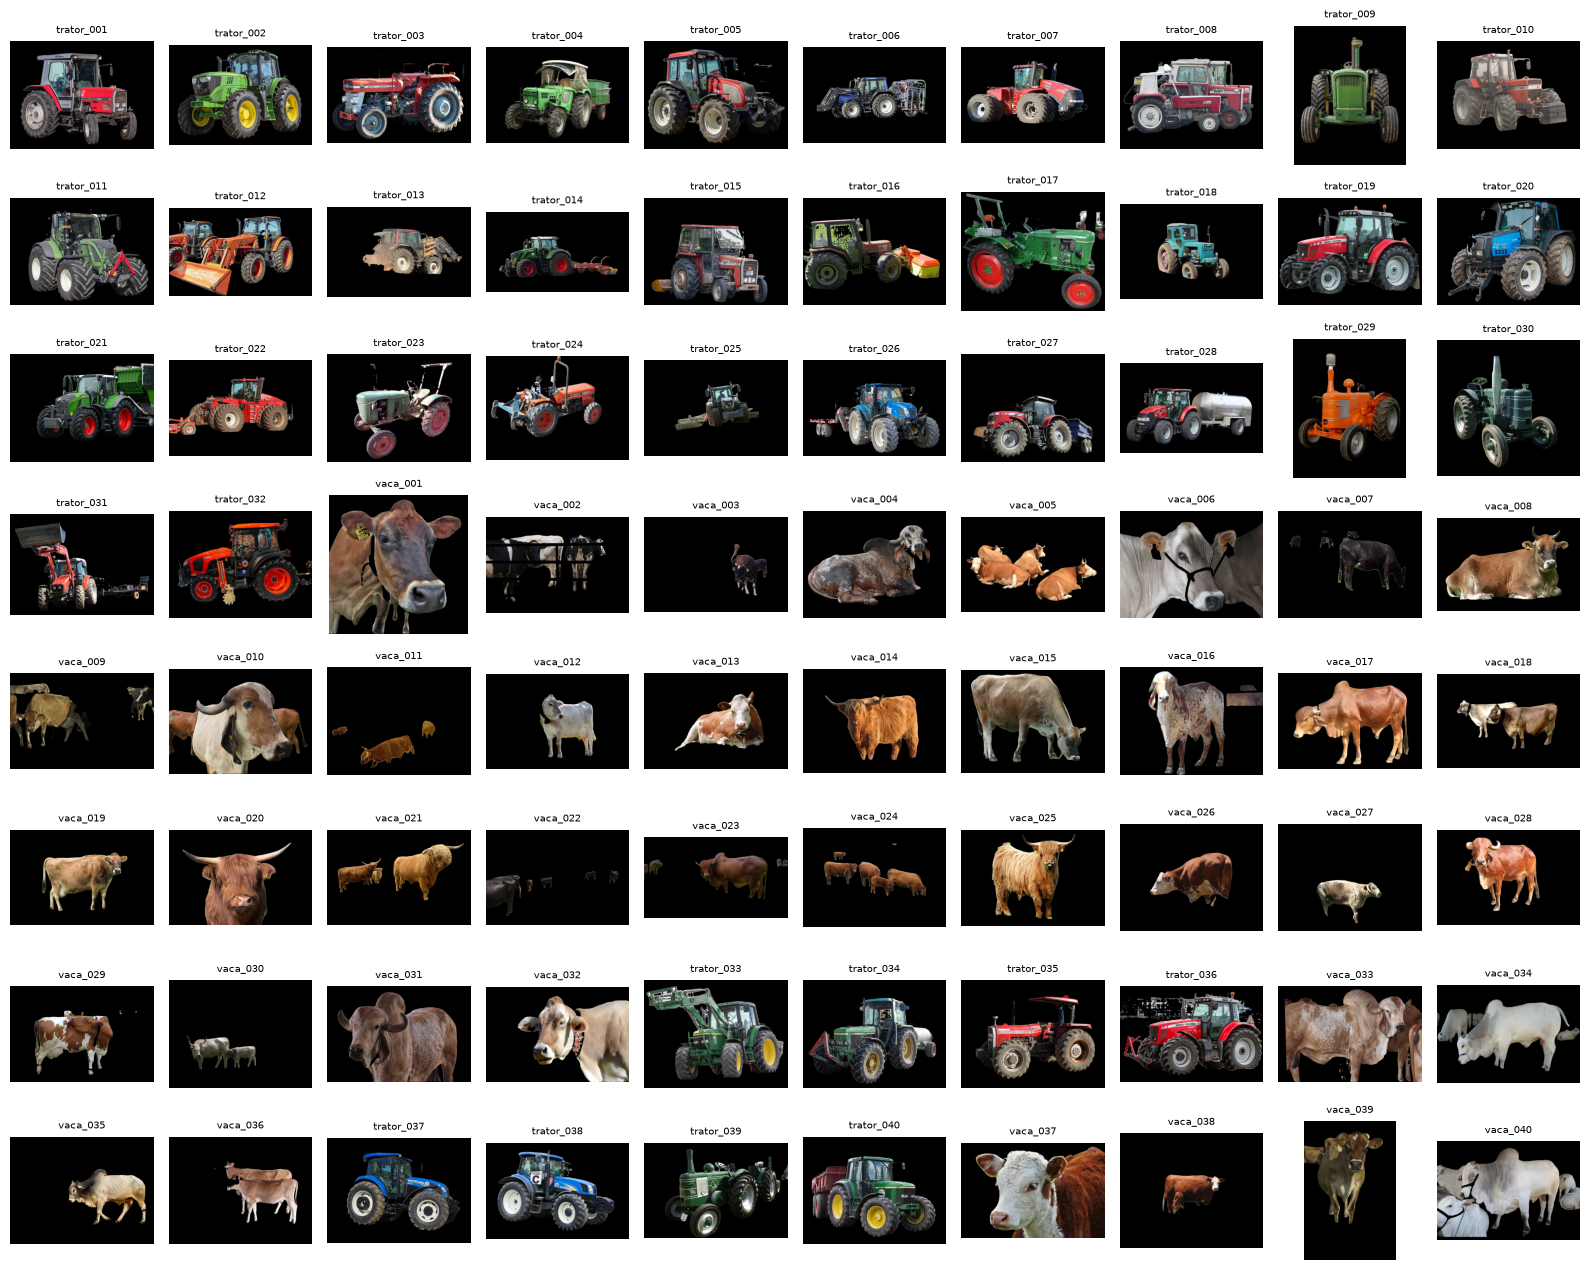

In [16]:
GALLERY_COLUMNS = 10


def plot_gallery(path):
    rows = int(np.ceil(len(segmentation_report) / GALLERY_COLUMNS))
    fig, axes = plt.subplots(rows, GALLERY_COLUMNS, figsize=(GALLERY_COLUMNS * 1.6, rows * 1.6))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, record in zip(axes.ravel(), segmentation_report.to_dict("records")):
        ax.imshow(Image.open(SEGMENTED_DIR / record["split"] / record["arquivo"]))
        ax.set_title(Path(record["arquivo"]).stem, fontsize=7, color="red" if record["fallback"] else "black")
    fig.tight_layout()
    fig.savefig(path, dpi=PHOTO_GRID_DPI, bbox_inches="tight")
    plt.show()


plot_gallery(FIGURES_DIR / "segmentacao_galeria.png")

### Treino nas imagens segmentadas

Libera a memória da GPU usada pelos modelos de segmentação, carrega o dataset segmentado (mesmos arquivos, mesmos splits) e repete exatamente o protocolo da Parte A: mesmos modelos, hiperparâmetros e sementes.

In [17]:
del detector, segmenter
torch.cuda.empty_cache()

segmented_data = load_dataset(SEGMENTED_DIR)
for model_name in TRAINERS:
    rows, histories = run_all_seeds(model_name, VARIANT_SEGMENTED, segmented_data)
    all_rows += rows
    all_histories[(model_name, VARIANT_SEGMENTED)] = histories

CNN do zero | Segmentada | semente 42: val 100,0% · teste 100,0% · val+teste 100,0% · treino 51 s


CNN do zero | Segmentada | semente 7: val 100,0% · teste 100,0% · val+teste 100,0% · treino 51 s


CNN do zero | Segmentada | semente 2024: val 100,0% · teste 100,0% · val+teste 100,0% · treino 51 s


MobileNetV2 (transfer + fine tuning) | Segmentada | semente 42: val 100,0% · teste 100,0% · val+teste 100,0% · treino 24 s


MobileNetV2 (transfer + fine tuning) | Segmentada | semente 7: val 100,0% · teste 100,0% · val+teste 100,0% · treino 23 s


MobileNetV2 (transfer + fine tuning) | Segmentada | semente 2024: val 100,0% · teste 100,0% · val+teste 100,0% · treino 25 s


### Curvas de aprendizado nas imagens segmentadas (semente 42)

Mesmo gráfico da Parte A, agora com fundo preto.

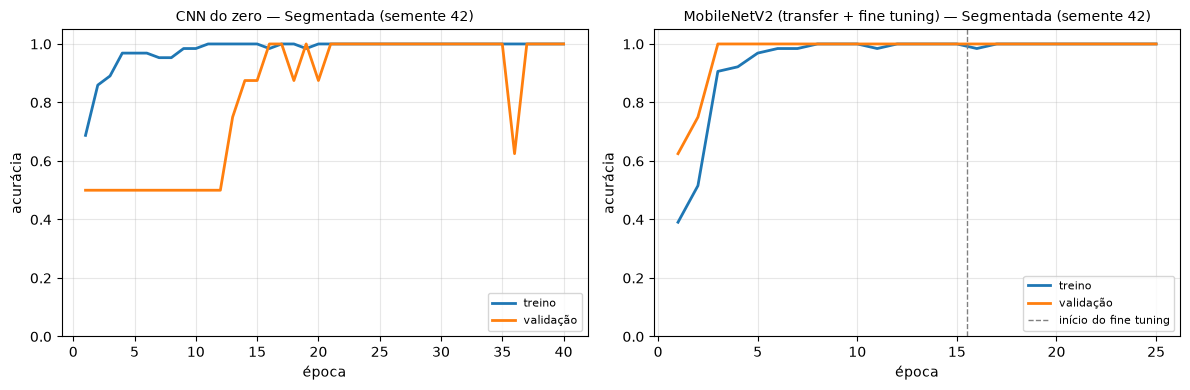

In [18]:
plot_learning_curves(VARIANT_SEGMENTED, FIGURES_DIR / "curvas_segmentada.png")

---
## Parte C — Comparação final

### Tabela das 4 combinações

Média ± desvio-padrão sobre as sementes 42, 7 e 2024. `acc_val_teste` junta validação e teste (16 imagens) para reduzir a granularidade: no teste puro cada erro vale 12,5 pontos percentuais. `logloss_val_teste` (entropia cruzada) diferencia modelos que acertam tudo mas com confiança diferente. Os tempos foram medidos no mesmo ambiente: treino e inferência no dispositivo `TF_DEVICE` impresso na célula de bibliotecas (CPU ou GPU, conforme a máquina); a inferência é por imagem, sobre o teste (8 imagens). A tabela também é salva em `figuras/comparacao_final.csv`.

In [19]:
results = pd.DataFrame(all_rows)
results.to_csv(FIGURES_DIR / "resultados_por_semente.csv", index=False)
final_table = summarize(all_rows)
final_table.to_csv(FIGURES_DIR / "comparacao_final.csv")
final_table

,,acc_treino,acc_val,acc_teste,acc_val_teste,logloss_val_teste,tempo_treino_s,inferencia_ms
modelo,imagens,,,,,,,
CNN do zero,Original,"0,922 ± 0,095","0,708 ± 0,191","0,917 ± 0,144","0,812 ± 0,165","0,846 ± 0,503","51,289 ± 0,322","7,090 ± 0,194"
MobileNetV2 (transfer + fine tuning),Original,"1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","0,002 ± 0,001","24,318 ± 0,566","28,030 ± 0,236"
CNN do zero,Segmentada,"0,995 ± 0,009","1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","0,008 ± 0,001","51,102 ± 0,383","6,829 ± 0,107"
MobileNetV2 (transfer + fine tuning),Segmentada,"1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","0,001 ± 0,001","23,926 ± 0,657","26,419 ± 1,966"


### Resultados por semente

Mostra cada execução individual, para evidenciar a variância entre sementes.

In [20]:
results.style.format(precision=3, decimal=",")

,modelo,imagens,semente,tempo_treino_s,acc_treino,acc_val,acc_teste,acc_val_teste,logloss_val_teste,inferencia_ms
0,CNN do zero,Original,42,"51,649","0,969","0,750","1,000","0,875","0,587","6,880"
1,CNN do zero,Original,7,"51,027","0,984","0,875","1,000","0,938","0,525","7,130"
2,CNN do zero,Original,2024,"51,191","0,812","0,500","0,750","0,625","1,426","7,262"
3,MobileNetV2 (transfer + fine tuning),Original,42,"23,677","1,000","1,000","1,000","1,000","0,003","28,000"
4,MobileNetV2 (transfer + fine tuning),Original,7,"24,534","1,000","1,000","1,000","1,000","0,001","27,811"
5,MobileNetV2 (transfer + fine tuning),Original,2024,"24,744","1,000","1,000","1,000","1,000","0,001","28,279"
6,CNN do zero,Segmentada,42,"50,673","1,000","1,000","1,000","1,000","0,007","6,714"
7,CNN do zero,Segmentada,7,"51,410","0,984","1,000","1,000","1,000","0,007","6,926"
8,CNN do zero,Segmentada,2024,"51,225","1,000","1,000","1,000","1,000","0,008","6,847"
9,MobileNetV2 (transfer + fine tuning),Segmentada,42,"23,654","1,000","1,000","1,000","1,000","0,001","24,301"


### Validação cruzada estratificada 5-fold (todas as 80 imagens)

Com 16 imagens de avaliação, cada erro move a acurácia em 6,25 p.p. Para uma estimativa menos frágil, junta treino+validação+teste (80 imagens) e roda **5-fold estratificado** (64 treino / 16 avaliação por fold, mesmas partições para as 4 combinações e para as duas versões das imagens). Cada imagem é avaliada exatamente uma vez por um modelo que não a viu. A versão segmentada usa os mesmos arquivos, na mesma ordem, de modo que a comparação é pareada.

In [21]:
CV_FOLDS = 5
CV_SEED = 42


def pool(data):
    return (np.concatenate([data[split]["x"] for split in SPLITS]),
            np.concatenate([data[split]["y"] for split in SPLITS]),
            [path.name for split in SPLITS for path in data[split]["paths"]])


def fold_data(x, y, train_index, eval_index):
    evaluation = {"x": x[eval_index], "y": y[eval_index]}
    return {"train": {"x": x[train_index], "y": y[train_index]}, "val": evaluation, "test": evaluation}


def run_cross_validation(model_name, variant, data):
    x, y, _ = pool(data)
    folds = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=CV_SEED).split(x, y)
    rows = []
    for fold, (train_index, eval_index) in enumerate(folds):
        row, _ = run_experiment(model_name, variant, fold_data(x, y, train_index, eval_index), CV_SEED)
        rows.append({**row, "fold": fold, "acertos": round(row["acc_teste"] * len(eval_index)), "n": len(eval_index)})
    total = sum(row["acertos"] for row in rows)
    print(f"{model_name} | {variant}: {total}/{len(y)} acertos ({percent(total / len(y))})")
    return rows


assert pool(original_data)[2] == pool(segmented_data)[2]
DATASETS = {VARIANT_ORIGINAL: original_data, VARIANT_SEGMENTED: segmented_data}
cv_rows = [row for variant, data in DATASETS.items() for model_name in TRAINERS
           for row in run_cross_validation(model_name, variant, data)]
cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(FIGURES_DIR / "validacao_cruzada.csv", index=False)
cv_summary = cv_results.groupby(["modelo", "imagens"], sort=False).agg(
    acertos=("acertos", "sum"), n=("n", "sum"), acc_media_folds=("acc_teste", "mean"),
    acc_desvio_folds=("acc_teste", "std"), logloss_media=("logloss_val_teste", "mean"),
    tempo_treino_s=("tempo_treino_s", "mean"))
cv_summary["acc_total"] = cv_summary["acertos"] / cv_summary["n"]
cv_summary.style.format(precision=3, decimal=",")

CNN do zero | Original: 66/80 acertos (82,5%)


MobileNetV2 (transfer + fine tuning) | Original: 80/80 acertos (100,0%)


CNN do zero | Segmentada: 78/80 acertos (97,5%)


MobileNetV2 (transfer + fine tuning) | Segmentada: 80/80 acertos (100,0%)


,,acertos,n,acc_media_folds,acc_desvio_folds,logloss_media,tempo_treino_s,acc_total
modelo,imagens,,,,,,,
CNN do zero,Original,66,80,"0,825","0,081","1,181","53,368","0,825"
MobileNetV2 (transfer + fine tuning),Original,80,80,"1,000","0,000","0,002","25,552","1,000"
CNN do zero,Segmentada,78,80,"0,975","0,034","0,105","53,694","0,975"
MobileNetV2 (transfer + fine tuning),Segmentada,80,80,"1,000","0,000","0,002","27,705","1,000"


### Gráfico comparativo

À esquerda, acurácia média em validação+teste (16 imagens) sobre as 3 sementes. À direita, acurácia da validação cruzada 5-fold sobre as 80 imagens. A altura da barra é a média. **A barra de erro vai do mínimo ao máximo** entre sementes (esquerda) ou folds (direita), e não ± desvio-padrão, que poderia ultrapassar 100%. Os pontos são as execuções individuais.

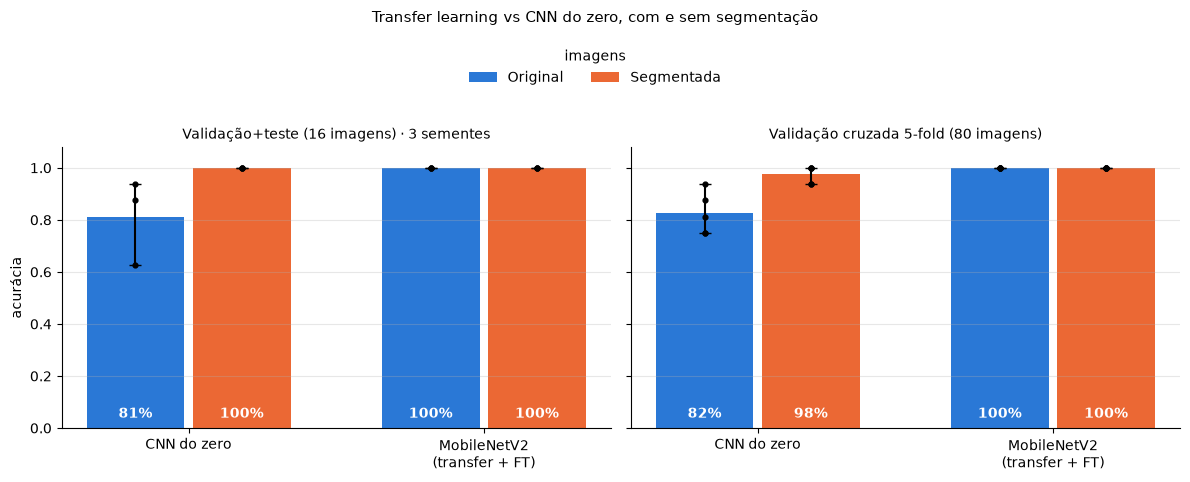

In [22]:
VARIANT_COLORS = {VARIANT_ORIGINAL: "#2a78d6", VARIANT_SEGMENTED: "#eb6834"}
BAR_WIDTH = 0.36


def draw_bars(ax, frame, metric, title):
    for offset, (variant, color) in zip((-BAR_WIDTH / 2, BAR_WIDTH / 2), VARIANT_COLORS.items()):
        for position, model_name in enumerate(TRAINERS):
            values = frame[(frame["modelo"] == model_name) & (frame["imagens"] == variant)][metric]
            center = position + offset
            spread = [[values.mean() - values.min()], [values.max() - values.mean()]]
            ax.bar(center, values.mean(), BAR_WIDTH * 0.92, yerr=spread, color=color, capsize=4,
                   label=variant if position == 0 else None)
            ax.scatter([center] * len(values), values, color="black", s=12, zorder=3)
            ax.text(center, 0.04, percent(values.mean(), 0), ha="center", color="white", fontsize=10, fontweight="bold")
    ax.set_xticks(range(len(TRAINERS)), ["CNN do zero", "MobileNetV2\n(transfer + FT)"])
    ax.set_ylim(0, 1.08)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)


def plot_comparison(path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    draw_bars(axes[0], results, "acc_val_teste", f"Validação+teste (16 imagens) · {len(SEEDS)} sementes")
    draw_bars(axes[1], cv_results, "acc_teste", f"Validação cruzada {CV_FOLDS}-fold (80 imagens)")
    axes[0].set_ylabel("acurácia")
    fig.suptitle("Transfer learning vs CNN do zero, com e sem segmentação", fontsize=11, y=1.06)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="imagens", loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()


plot_comparison(FIGURES_DIR / "comparacao_final.png")

### Conclusões numéricas (geradas a partir dos resultados)

A célula abaixo monta a tabela final e os vereditos das hipóteses **a partir dos DataFrames desta execução** (`results`, `cv_results`, `segmentation_report`). Se o notebook for reexecutado (por exemplo no Colab, com GPU para o TensorFlow), todos os números e vereditos se atualizam sozinhos. Os critérios de decisão são:

* **Hipótese A:** compara o número de erros na validação cruzada 5-fold (80 imagens) entre MobileNetV2 e CNN do zero nas imagens originais.
* **Hipótese B:** para cada modelo, compara os erros na validação cruzada entre imagens originais e segmentadas e conta em quantos folds houve melhora ou piora. Se o modelo já tem 0 erros nas duas versões, o resultado é declarado como efeito de teto.

In [23]:
COMBINATIONS = [(model_name, variant) for variant in DATASETS for model_name in TRAINERS]


def select(frame, model_name, variant):
    return frame[(frame["modelo"] == model_name) & (frame["imagens"] == variant)]


def cv_errors(model_name, variant):
    folds = select(cv_results, model_name, variant)
    return int(folds["n"].sum() - folds["acertos"].sum())


def cv_total(model_name, variant):
    return int(select(cv_results, model_name, variant)["n"].sum())


def mean_of(frame, model_name, variant, metric):
    return select(frame, model_name, variant)[metric].mean()


def table_row(model_name, variant):
    seeds = select(results, model_name, variant)["acc_val_teste"]
    total, errors = cv_total(model_name, variant), cv_errors(model_name, variant)
    return (f"| {model_name} · {variant.lower()} | {percent(seeds.mean())} (mín {percent(seeds.min())}, máx {percent(seeds.max())}) "
            f"| {percent(mean_of(results, model_name, variant, 'acc_teste'))} "
            f"| {decimal(mean_of(results, model_name, variant, 'logloss_val_teste'), 3)} "
            f"| {total - errors}/{total} = {percent((total - errors) / total)} "
            f"| {decimal(mean_of(cv_results, model_name, variant, 'logloss_val_teste'), 3)} "
            f"| {decimal(mean_of(results, model_name, variant, 'tempo_treino_s'), 0)} "
            f"| {decimal(mean_of(results, model_name, variant, 'inferencia_ms'))} |")


def results_table():
    header = ("| Combinação | Val+teste, 16 img (média de 3 sementes) | Teste, 8 img | Log-loss val+teste | CV 5-fold, 80 img "
              "| Log-loss CV | Treino (s) | Inferência (ms/img) |")
    return [header, "|" + "---|" * 8] + [table_row(*combination) for combination in COMBINATIONS]


def fold_changes(model_name):
    before = select(cv_results, model_name, VARIANT_ORIGINAL).set_index("fold")["acertos"]
    after = select(cv_results, model_name, VARIANT_SEGMENTED).set_index("fold")["acertos"]
    return int((after > before).sum()), int((after < before).sum())


def hypothesis_a():
    scratch, transfer = cv_errors(MODEL_SCRATCH, VARIANT_ORIGINAL), cv_errors(MODEL_TRANSFER, VARIANT_ORIGINAL)
    total = cv_total(MODEL_SCRATCH, VARIANT_ORIGINAL)
    verdict = "confirmada" if transfer < scratch else "refutada" if transfer > scratch else "inconclusiva (empate)"
    scratch_seeds = select(results, MODEL_SCRATCH, VARIANT_ORIGINAL)["acc_val_teste"]
    times = [mean_of(results, model_name, VARIANT_ORIGINAL, "tempo_treino_s") for model_name in (MODEL_SCRATCH, MODEL_TRANSFER)]
    return (f"**Hipótese A: rede pré-treinada vs treinada do zero ({verdict}).** Na validação cruzada com imagens originais, "
            f"a MobileNetV2 errou {transfer} de {total} imagens e a CNN do zero errou {scratch}. Entre sementes, o val+teste da CNN do zero "
            f"variou de {percent(scratch_seeds.min())} a {percent(scratch_seeds.max())}. Tempo médio de treino: "
            f"{decimal(times[0], 0)} s (do zero) contra {decimal(times[1], 0)} s (transfer). O fine tuning ajustou "
            f"{thousands(unfrozen_parameters)} de {thousands(inspection_base.count_params())} parâmetros da base.")


def segmentation_effect(model_name):
    before, after = cv_errors(model_name, VARIANT_ORIGINAL), cv_errors(model_name, VARIANT_SEGMENTED)
    better, worse = fold_changes(model_name)
    losses = [mean_of(cv_results, model_name, variant, "logloss_val_teste") for variant in DATASETS]
    if before == after == 0:
        return (f"* **{model_name}: efeito de teto.** 0 erros na CV com e sem segmentação; o log-loss médio foi de "
                f"{decimal(losses[0], 3)} para {decimal(losses[1], 3)}. Não há margem de acurácia para medir ganho.")
    verdict = "ajudou" if after < before else "atrapalhou" if after > before else "não mudou o número de erros"
    return (f"* **{model_name}: a segmentação {verdict}.** Erros na CV: {before} → {after}. Melhorou em {better} e piorou em "
            f"{worse} dos {CV_FOLDS} folds. Log-loss médio: {decimal(losses[0], 3)} → {decimal(losses[1], 3)}.")


def segmentation_summary():
    total = len(segmentation_report)
    milliseconds = 1000 * segmentation_seconds / total
    return (f"**Segmentação automática:** {total - len(fallbacks)} de {total} imagens com máscara e {len(fallbacks)} fallback(s); "
            f"{decimal(milliseconds, 0)} ms/imagem em `{TORCH_DEVICE}`, contra {decimal(results['inferencia_ms'].mean())} ms/imagem "
            f"em média para os classificadores.")


def best_combinations():
    accuracy = {combination: 1 - cv_errors(*combination) / cv_total(*combination) for combination in COMBINATIONS}
    top = max(accuracy.values())
    names = [f"{model_name} · {variant.lower()}" for (model_name, variant), value in accuracy.items() if value == top]
    return f"**Melhor resultado na CV ({percent(top)}):** {' / '.join(names)}."


lines = results_table() + ["", hypothesis_a(), "", "**Hipótese B: segmentar antes de classificar ajuda?**"]
lines += [segmentation_effect(model_name) for model_name in TRAINERS]
lines += ["", segmentation_summary(), "", best_combinations()]
display(Markdown("\n".join(lines)))

| Combinação | Val+teste, 16 img (média de 3 sementes) | Teste, 8 img | Log-loss val+teste | CV 5-fold, 80 img | Log-loss CV | Treino (s) | Inferência (ms/img) |
|---|---|---|---|---|---|---|---|
| CNN do zero · original | 81,2% (mín 62,5%, máx 93,8%) | 91,7% | 0,846 | 66/80 = 82,5% | 1,181 | 51 | 7,1 |
| MobileNetV2 (transfer + fine tuning) · original | 100,0% (mín 100,0%, máx 100,0%) | 100,0% | 0,002 | 80/80 = 100,0% | 0,002 | 24 | 28,0 |
| CNN do zero · segmentada | 100,0% (mín 100,0%, máx 100,0%) | 100,0% | 0,008 | 78/80 = 97,5% | 0,105 | 51 | 6,8 |
| MobileNetV2 (transfer + fine tuning) · segmentada | 100,0% (mín 100,0%, máx 100,0%) | 100,0% | 0,001 | 80/80 = 100,0% | 0,002 | 24 | 26,4 |

**Hipótese A: rede pré-treinada vs treinada do zero (confirmada).** Na validação cruzada com imagens originais, a MobileNetV2 errou 0 de 80 imagens e a CNN do zero errou 14. Entre sementes, o val+teste da CNN do zero variou de 62,5% a 93,8%. Tempo médio de treino: 51 s (do zero) contra 24 s (transfer). O fine tuning ajustou 1.194.880 de 2.257.984 parâmetros da base.

**Hipótese B: segmentar antes de classificar ajuda?**
* **CNN do zero: a segmentação ajudou.** Erros na CV: 14 → 2. Melhorou em 5 e piorou em 0 dos 5 folds. Log-loss médio: 1,181 → 0,105.
* **MobileNetV2 (transfer + fine tuning): efeito de teto.** 0 erros na CV com e sem segmentação; o log-loss médio foi de 0,002 para 0,002. Não há margem de acurácia para medir ganho.

**Segmentação automática:** 80 de 80 imagens com máscara e 0 fallback(s); 184 ms/imagem em `cuda:0`, contra 17,1 ms/imagem em média para os classificadores.

**Melhor resultado na CV (100,0%):** MobileNetV2 (transfer + fine tuning) · original / MobileNetV2 (transfer + fine tuning) · segmentada.

### Interpretação

**Por que a rede pré-treinada tende a vencer.** Com 64 imagens de treino, a CNN do zero precisa aprender ao mesmo tempo filtros de borda e textura, partes de objetos e a fronteira de decisão. As curvas de aprendizado mostram o sintoma típico: a acurácia de treino chega perto de 100%, mas a validação oscila muito entre épocas, ou seja, ela decora as imagens. A MobileNetV2 já chega com esses filtros prontos (a ImageNet inclui as classes *ox* e *tractor*), então a cabeça nova separa as classes em poucas épocas mesmo com a base congelada. O fine tuning do topo com LR baixo e BatchNorm congelado serve mais para refinar a confiança (log-loss) do que para corrigir erros, que já são raros nessa fase.

**Por que a segmentação pode ajudar a CNN do zero e pouco a MobileNetV2.** Sem fundo, um modelo com pouca informação prévia não consegue usar atalhos como "pasto verde = vaca" e "asfalto ou galpão = trator", e passa a aprender só o objeto, inclusive a silhueta, que sozinha já é bem discriminativa. Uma rede pré-treinada já foca no objeto. Se ela está perto de 100% nas imagens originais, a segmentação não tem erro para corrigir (efeito de teto) e, no máximo, muda a confiança. Os vereditos acima dizem, para esta execução, se o ganho apareceu e em quantos folds.

**Custo e utilidade prática.** A segmentação (YOLO-World + CLIP + SAM 2, mais de 100 M parâmetros pré-treinados) é muito mais cara por imagem do que os classificadores (ver a linha "Segmentação automática" acima) e precisaria rodar também em produção, sobre cada imagem nova. Além disso, o YOLO-World recebe os textos "cow"/"tractor" e já é, por si só, quase um classificador zero-shot. Descartamos a classe que ele prevê, mas parte do ganho da CNN do zero vem, indiretamente, desses modelos pré-treinados. Se a MobileNetV2 já resolve o problema nas imagens originais, **transfer learning sozinho tem a melhor relação custo/benefício**. Pré-segmentar vale a pena quando não há uma rede pré-treinada adequada ou quando se sabe que o fundo é um atalho enganoso, por exemplo quando todas as vacas de treino estão no pasto e na produção aparecem no curral.

**Qualidade das máscaras.** A galeria completa mostra máscaras precisas na grande maioria das imagens. As imperfeições que observamos são pequenas: em rebanhos com muitos animais, só as 6 caixas mais confiáveis são segmentadas (animais distantes podem ficar de fora), objetos parecidos às vezes entram na máscara (uma pedra em vaca_022), e cercas na frente do animal cortam a máscara (vaca_002).

### Limitações

* **Conjunto de avaliação minúsculo:** no split original o teste tem 8 imagens (cada erro vale 12,5 p.p.) e val+teste tem 16. Por isso reportamos 3 sementes e validação cruzada 5-fold. Mesmo assim, 80 imagens não bastam para afirmar perfeição: para 80/80 acertos, o limite inferior do intervalo de confiança de 95% da acurácia real fica em torno de 96%.
* **Variância entre sementes e folds:** a dispersão da CNN do zero (barras mín–máx no gráfico) é da mesma ordem das diferenças entre combinações. A direção de um efeito é mais confiável do que sua magnitude.
* **Tempos aproximados:** dependem do dispositivo (`TF_DEVICE`, impresso na célula de bibliotecas) e de outros processos na máquina. Não compare tempos entre execuções em máquinas diferentes. A arquitetura é a mesma para imagens originais e segmentadas, então diferenças de tempo de inferência entre essas duas variantes são ruído de medição.
* **Hiperparâmetros fixos** (épocas, LR, ponto de corte do fine tuning) escolhidos a priori, sem busca. Com 8 imagens de validação, ajustá-los seria sobreajustar a validação.
* **Dataset da web:** fotos com o objeto centralizado e bem enquadrado. Imagens de câmeras de fazenda (noite, oclusão, objeto pequeno) seriam mais difíceis tanto para a segmentação quanto para a classificação.
* **Não determinismo:** mesmo com sementes fixas, operações de CPU/GPU podem variar ligeiramente entre execuções e máquinas. Por isso os números são gerados pela célula acima, e não escritos à mão.
* **Duas armadilhas do Keras 3 que viraram decisões de projeto:** o BatchNorm da CNN do zero usa `momentum=0.9` (com o padrão 0,99 ela previa uma única classe), e os BatchNorms da MobileNetV2 ficam congelados no fine tuning (`training=False` na chamada não basta quando a camada está `trainable`).